Dataset shape: (852, 25)

First five rows:
   S.No                                          Item name Brand_Name  \
0     1                                      HIDE & SEEK®       PARLE   
1     2  Britannia Nutrichoice Digestive High-Fibre Bis...  BRITANNIA   
2     3  Sunfeast Dark Fantasy Choco Fills, Original Fi...   SUNFEAST   
3     4   Sunfeast Baked Creations Rich Choco Chip Cookies   SUNFEAST   
4     5  sunfeast Dark Fantasy Bourbon, Classic Biscuit...   SUNFEAST   

  Category       Sub_Category  \
0  BISCUIT            COOKIES   
1  BISCUIT  DIGESTIVE BISCUIT   
2  BISCUIT        CHOCO FILLS   
3  BISCUIT            COOKIES   
4  BISCUIT             CREAME   

                                         Ingredients  Serving_Size_g  \
0  REFINED WHEAT FLOUR (MAIDA), CHOCOLATE (23%)  ...           100.0   
1  WHEAT FLOUR (ATTA) (65.5%), REFINED PALM OIL, ...           100.0   
2   SUGAR, REFINED PALMOLEIN, REFINED PALM OIL, C...           100.0   
3  MAIDA (REFINED WHEAT FLOUR),

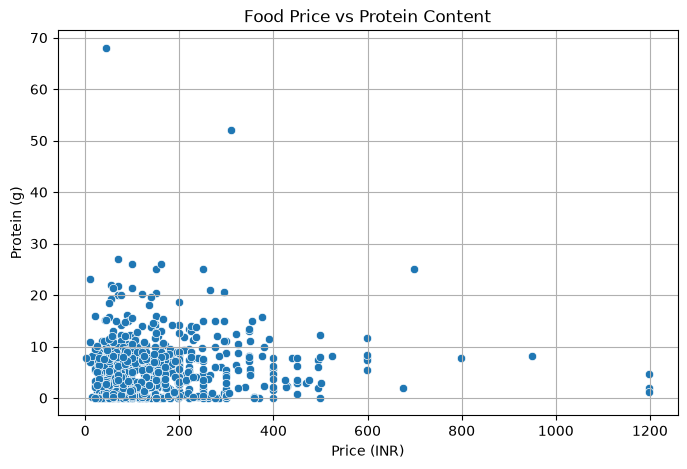

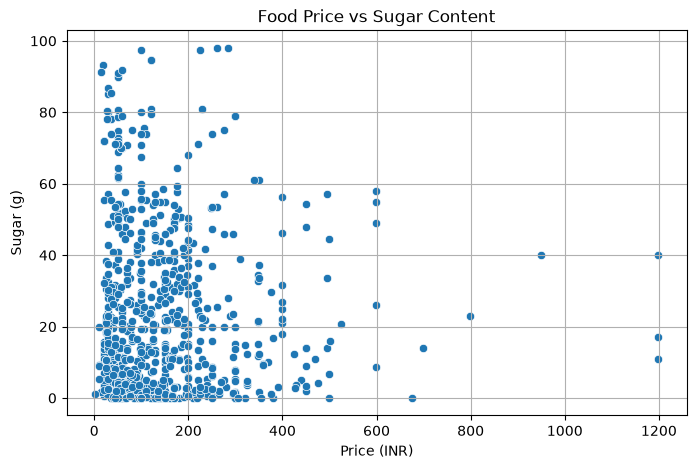

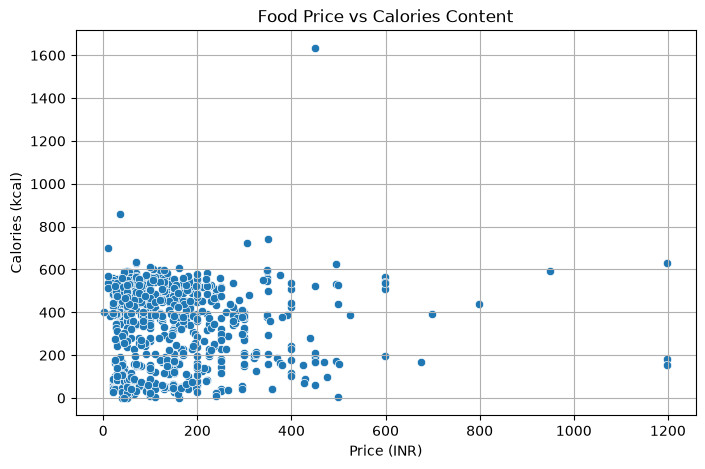


Price vs Protein
Spearman correlation: 0.036
P-value: 0.2988159708261473

Price vs Sugar
Spearman correlation: 0.0124
P-value: 0.7198557251900256

Price vs Calories
Spearman correlation: -0.0941
P-value: 0.006500868342586998

INTERPRETATION
No statistically significant association between price and protein.
No statistically significant association between price and sugar.
Price and calories have a statistically significant association.


In [4]:
# STEP 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# STEP 2: Load dataset

df = pd.read_csv("packaged_foods_india.csv")

# STEP 3: Inspect dataset

print("Dataset shape:", df.shape)

print("\nFirst five rows:")
print(df.head())

print("\nMissing values:")
print(df.isnull().sum())

# STEP 4: Select required columns

price_col = "Price_INR"
protein_col = "Proteins_g"
sugar_col = "Sugar_g"
calories_col = "Calories_kcal"

# STEP 5: Convert columns to numeric

for col in [price_col, protein_col, sugar_col, calories_col]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with missing values in selected columns

data = df[
    [price_col, protein_col, sugar_col, calories_col]
].dropna()

# Remove invalid values

data = data[
    (data[price_col] > 0) &
    (data[protein_col] >= 0) &
    (data[sugar_col] >= 0) &
    (data[calories_col] >= 0)
]

print("\nCleaned dataset shape:", data.shape)

# STEP 6: Descriptive statistics

print("\nDescriptive statistics:")
print(data.describe())

# STEP 7: Scatter plot - Price vs Protein

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=data,
    x=price_col,
    y=protein_col
)

plt.title("Food Price vs Protein Content")
plt.xlabel("Price (INR)")
plt.ylabel("Protein (g)")
plt.grid(True)
plt.show()


plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=data,
    x=price_col,
    y=sugar_col
)

plt.title("Food Price vs Sugar Content")
plt.xlabel("Price (INR)")
plt.ylabel("Sugar (g)")
plt.grid(True)
plt.show()


plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=data,
    x=price_col,
    y=calories_col
)

plt.title("Food Price vs Calories Content")
plt.xlabel("Price (INR)")
plt.ylabel("Calories (kcal)")
plt.grid(True)
plt.show()


# STEP 8: Statistical analysis

# Price vs Protein

r1, p1 = spearmanr(data[price_col], data[protein_col])

print("\nPrice vs Protein")
print("Spearman correlation:", round(r1, 4))
print("P-value:", p1)

# Price vs Sugar

r2, p2 = spearmanr(data[price_col], data[sugar_col])

print("\nPrice vs Sugar")
print("Spearman correlation:", round(r2, 4))
print("P-value:", p2)

# Price vs Calories

r3, p3 = spearmanr(data[price_col], data[calories_col])

print("\nPrice vs Calories")
print("Spearman correlation:", round(r3, 4))
print("P-value:", p3)

# STEP 9: Interpret results

print("\nINTERPRETATION")

if p1 < 0.05:
    print("Price and protein have a statistically significant association.")
else:
    print("No statistically significant association between price and protein.")

if p2 < 0.05:
    print("Price and sugar have a statistically significant association.")
else:
    print("No statistically significant association between price and sugar.")

if p3 < 0.05:
    print("Price and calories have a statistically significant association.")
else:
    print("No statistically significant association between price and calories.")